## Norrmalized Feature Extractrion

- First upload following files on your google drive:
  - zip format of enrollment
  - zip format of verification
  - gt.txt 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
!pip install git+https://github.com/wannesm/dtaidistance.git#egg=dtaidistance
from dtaidistance import dtw
from dtaidistance import dtw_ndim
from dtaidistance import dtw_visualisation as dtwvis

  Cloning https://github.com/wannesm/dtaidistance.git to /tmp/pip-install-vh_0kc_7/dtaidistance
  Running command git clone -q https://github.com/wannesm/dtaidistance.git /tmp/pip-install-vh_0kc_7/dtaidistance
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
    Preparing wheel metadata ... done
  Created wheel for dtaidistance: filename=dtaidistance-2.2.5-cp37-cp37m-linux_x86_64.whl size=1567501 sha256=cc62205467b10bdd92dcc406094be92b07d3bdd52a73236bf64451c59f0944c4
  Stored in directory: /tmp/pip-ephem-wheel-cache-1ofo2clv/wheels/79/23/2e/a5c573240861bbe549111821c15b7cf93d3a1407064bad9301
Successfully built dtaidistance


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
! unzip "/content/drive/MyDrive/Colab Notebooks/enrollment.zip"

Archive:  /content/drive/MyDrive/Colab Notebooks/enrollment.zip
  inflating: enrollment/001-g-01.txt  
  inflating: enrollment/001-g-02.txt  
  inflating: enrollment/001-g-03.txt  
  inflating: enrollment/001-g-04.txt  
  inflating: enrollment/001-g-05.txt  
  inflating: enrollment/002-g-01.txt  
  inflating: enrollment/002-g-02.txt  
  inflating: enrollment/002-g-03.txt  
  inflating: enrollment/002-g-04.txt  
  inflating: enrollment/002-g-05.txt  
  inflating: enrollment/003-g-01.txt  
  inflating: enrollment/003-g-02.txt  
  inflating: enrollment/003-g-03.txt  
  inflating: enrollment/003-g-04.txt  
  inflating: enrollment/003-g-05.txt  
  inflating: enrollment/004-g-01.txt  
  inflating: enrollment/004-g-02.txt  
  inflating: enrollment/004-g-03.txt  
  inflating: enrollment/004-g-04.txt  
  inflating: enrollment/004-g-05.txt  
  inflating: enrollment/005-g-01.txt  
  inflating: enrollment/005-g-02.txt  
  inflating: enrollment/005-g-03.txt  
  inflating: enrollment/005-g-04.txt  


In [4]:
!unzip '/content/drive/MyDrive/Colab Notebooks/verification.zip'

Archive:  /content/drive/MyDrive/Colab Notebooks/verification.zip
  inflating: verification/001-01.txt  
  inflating: verification/001-02.txt  
  inflating: verification/001-03.txt  
  inflating: verification/001-04.txt  
  inflating: verification/001-05.txt  
  inflating: verification/001-06.txt  
  inflating: verification/001-07.txt  
  inflating: verification/001-08.txt  
  inflating: verification/001-09.txt  
  inflating: verification/001-10.txt  
  inflating: verification/001-11.txt  
  inflating: verification/001-12.txt  
  inflating: verification/001-13.txt  
  inflating: verification/001-14.txt  
  inflating: verification/001-15.txt  
  inflating: verification/001-16.txt  
  inflating: verification/001-17.txt  
  inflating: verification/001-18.txt  
  inflating: verification/001-19.txt  
  inflating: verification/001-20.txt  
  inflating: verification/001-21.txt  
  inflating: verification/001-22.txt  
  inflating: verification/001-23.txt  
  inflating: verification/001-24.txt 

In [5]:
# Convert each text file into a numpy array
def file2array(file_path, dtype):
  array_from_file = np.loadtxt(file_path, dtype)
  return array_from_file

## Load the Data

In [6]:
num_writers = 30    #Number of writers
num_gen_sig = 5     #Number of genuine signatures per writers
num_sig = 45        #Number of signatures per writers which should be verified

# Enrollment
enrollment = []
for i in range(num_writers):
  for j in range (num_gen_sig):
    if (len(str(i+1))==1):
      file_path = '/content/enrollment/00{}-g-0{}.txt'.format(i+1,j+1)
    else:
      file_path = '/content/enrollment/0{}-g-0{}.txt'.format(i+1,j+1)
    array_from_file = file2array(file_path, dtype=float)
    enrollment.append(array_from_file)

# Verification
verification = []
for i in range(num_writers):
  for j in range (num_sig):
    if (len(str(i+1))==1 and len(str(j+1))==1):
      file_path = '/content/verification/00{}-0{}.txt'.format(i+1,j+1)
    elif (len(str(i+1))==1 and len(str(j+1))==2) :
      file_path = '/content/verification/00{}-{}.txt'.format(i+1,j+1)
    elif (len(str(i+1))==2 and len(str(j+1))==1) :
      file_path = '/content/verification/0{}-0{}.txt'.format(i+1,j+1)
    else:
      file_path = '/content/verification/0{}-{}.txt'.format(i+1,j+1)
    
    array_from_file = file2array(file_path, dtype=float)
    verification.append(array_from_file)

# Ground truth
gt = file2array('/content/drive/MyDrive/Colab Notebooks/gt.txt', dtype=str)

In [7]:
print('The whole enrollment data:',len(enrollment))
print('The whole verification data:',len(verification))
print('Ground truth size:', gt.shape)

The whole enrollment data: 150
The whole verification data: 1350
Ground truth size: (1350, 2)


In [8]:
#All Signature related to each writer
def writer(idx):    # idx: Writer Number from 1 to 30
  writer_enr = enrollment[5*(idx-1):5*idx]
  writer_ver = verification[45*(idx-1):45*idx]
  return writer_enr, writer_ver

In [9]:
#Feature normalization
def normalization(input,epsilon=1e-100):
  return np.array([(np.array(input)-np.array(input).mean())/(np.array(input).std()+epsilon)])

In [10]:
#Normalized Features of each signature:[norm_x, norm_y, norm_vx, norm_vy, norm_pressure]
def norm_feature_sg(sg):
  x = []
  y = []
  vx = []
  vy = []
  pressure = []
  for i in range(len(sg)-1):
    x.append(sg[i][1])
    y.append(sg[i][2])
    pressure.append(sg[i][3])
    
    v_x = (sg[i+1][1]-sg[i][1])/(sg[i+1][0]-sg[i][0])
    v_y = (sg[i+1][2]-sg[i][2])/(sg[i+1][0]-sg[i][0])

    vx.append(v_x)
    vy.append(v_y)

  # Normalizing each feature separately
  norm_x = normalization(x)
  norm_y = normalization(y)
  norm_vx = normalization(vx)
  norm_vy = normalization(vy)
  norm_pressure = normalization(pressure)

  return np.concatenate((norm_x, norm_y, norm_vx, norm_vy, norm_pressure)).T

In [11]:
def feature_plot(list_sg, sg_cat):
  for i in range(len(list_sg)):
    # All Features of each signature
    f = norm_feature_sg(list_sg[i])   
    
    plt.figure()
    plt.title("Feature of {} signature{}".format(sg_cat, i+1))
    plt.plot(f[:,0],'r.',label="x")
    plt.plot(f[:,1],'b.',label="y")
    plt.plot(f[:,2],'g.',label="vx")
    plt.plot(f[:,3],'c.',label="vy")
    plt.plot(f[:,4],'m.',label="pressure")
    plt.legend(loc="lower left")

For example:
All the Enrollment & Verfication signatures list related to writer 1

In [12]:
# For example:
#All the Enrollment & Verfication signatures list related to writer 1
enr1, ver1 = writer(1)
# To extract feature of each signature use "norm_feature_sg(signature)" like what happened in below function 
# Working lines to create all enrN and verN for all writer(N)
#for n in range(1, 31):
#  globals()['enr%s' % n] = writer(n)[0]
#  globals()['ver%s' % n] = writer(n)[1]

To extract feature of each signature use "norm_feature_sg(signature)" like what happened in below function 
Feature Ploting for each enrolled signature of writer 1

Enrolled signature features of writer 1:


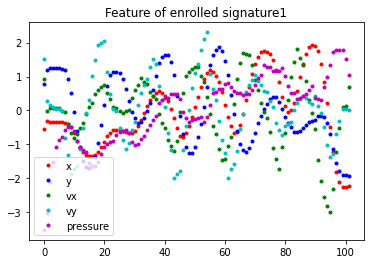

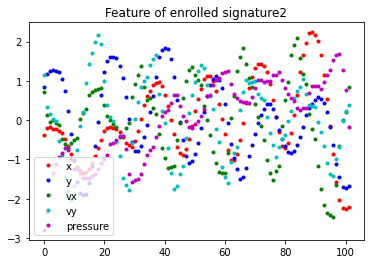

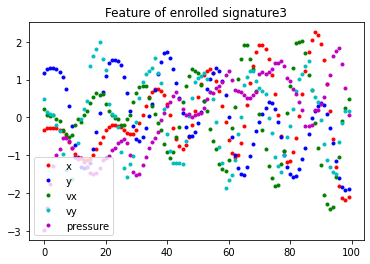

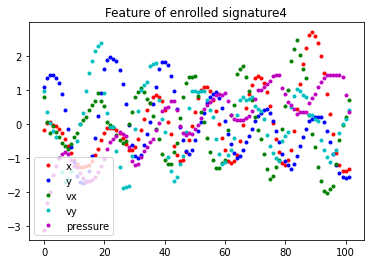

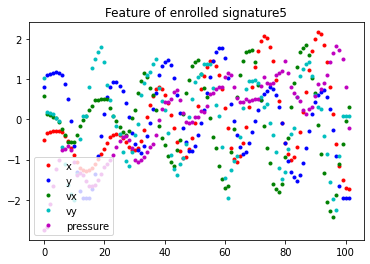

In [13]:
# Feature Ploting for each enrolled signature of writer 1 
print('Enrolled signature features of writer 1:')
feature_plot(enr1, 'enrolled')

Feature Ploting for each of top5 verification signatures of writer 1 

Top5 verification signature features of writer 1:


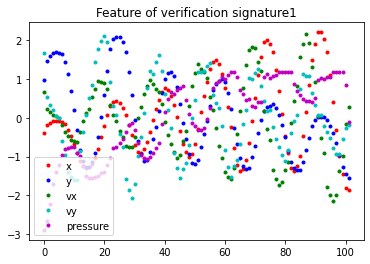

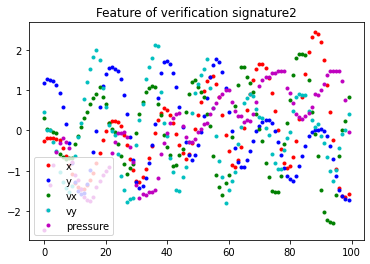

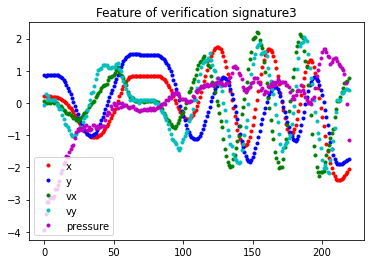

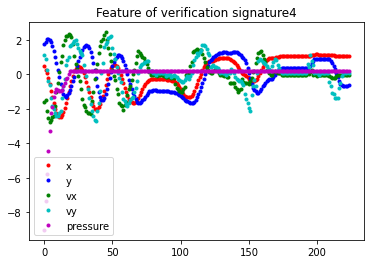

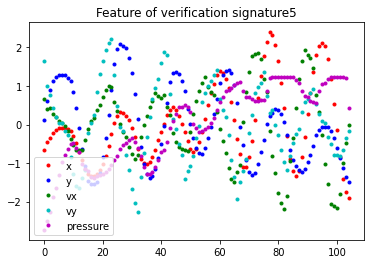

In [14]:
# Feature Ploting for each of top5 verification signatures of writer 1 
print('Top5 verification signature features of writer 1:')
feature_plot(ver1[0:5], 'verification')

# Normalization of enr and ver

In [15]:
def normalize_length_generic (ToNorm):

  New = []
  for i in range(5):
     size = len(ToNorm[i])
    #  print(size)
     New.append([])
     if(size>100):
       for j in range(100):
          New[i].append([])
     else: 
       for j in range(len(ToNorm[i])):
          New[i].append([])
    #  print(np.array(New[i]).shape)
  for i in range(0,5):
    size = len(ToNorm[i])    
    rowInTable = []
    
    if(size >100):
          
      for j in range(0,100):
        length = len(ToNorm[i])
        rowInTable.append(round(length*j/100))
      
      for j in range (0,100):
        
        New[i][j] = ToNorm[i][(rowInTable[j])]
    else:

      for j in range(size):
        # print(ToNorm[i][j])
        New[i][j] = ToNorm[i][j]
    #     print(New[i][j])
    # print(New)
  return New

##Calculating DTW

run DTW for each user to calculate percision and recall for each usert

In [16]:
#run DTW for each user to calculate percision and recall for each usert
def dtw_each_user(distance_for_matching, f_enr, f_ver, user_id):
  
  total_TP = 0
  total_FP = 0
  total_FN = 0
  total_TN = 0

  for i in range(0,len(f_enr)):
    for j in range(0,len(f_ver)):
      #print(i,j)
      distance, paths = dtw_ndim.warping_paths(f_enr[i], f_ver[j])  
      
      if (distance < distance_for_matching):
        if (str(gt[((user_id-1)*45)+(j)])[11:-2] == 'g'):
          total_TP += 1
        else:
          total_FP += 1
      else:
        if (str(gt[((user_id-1)*45)+(j)])[11:-2] == 'g'):
          total_FN += 1
        else:
          total_TN += 1
  
  if (total_TP+total_FP != 0 and total_TP+total_FN != 0):
    precision = total_TP/(total_TP+total_FP)
    recall = total_TP/(total_TP+total_FN)
    f_score = (2*precision*recall)/(precision + recall)
  else:
    precision = 0
    recall = 0
    f_score = 0
  
  
  return  precision, recall, f_score

In [17]:
#this function compute avrarge recall and precision for all users for given distance
def dtw_user(distance):

  all_precision=[]
  all_recall=[]
  all_fscore=[]

  for user_id in range(1,31):
    
    enr,ver = writer(user_id)
    enr = normalize_length_generic(enr)
    ver = normalize_length_generic(ver)
    
    #print(user_id)

    f_enr = []
    f_ver = []
    for i in range(len(enr)):
      f_enr.append(norm_feature_sg(enr[i])) 

    for i in range(len(ver)):
      f_ver.append(norm_feature_sg(ver[i]))

    precision, recall, fscore = dtw_each_user( distance,f_enr,f_ver,user_id)

    all_precision.append(precision)
    all_recall.append(recall)
    all_fscore.append(fscore)

    #print(all_precision,all_recall)

  avg_recall = np.mean(all_recall) 
  avg_precision = np.mean(all_precision)
  avg_fscore = np.mean(all_fscore) 


  return avg_recall, avg_precision, avg_fscore


In [18]:
#this calculate best distance for whole data in many epoch
def epoch_all_user(num_epoch, steps, starting_distance):
  
  distance_for_matching = starting_distance
  all_avg_distance =[]
  all_avg_recall =[]
  all_avg_precision =[]
  all_avg_fscore =[]

  for i in range(num_epoch):
    print("epoch"+str(i+1))
    avg_recall, avg_precision, avg_fscore = dtw_user(distance_for_matching)
    all_avg_distance.append(distance_for_matching)
    all_avg_recall.append(avg_recall)
    all_avg_precision.append(avg_precision)
    all_avg_fscore.append(avg_fscore)
    
    distance_for_matching -= steps
  
  
  return all_avg_distance, all_avg_recall, all_avg_precision, all_avg_fscore


###calculating best distance for the first writer
We initially set the distance to 30, and then in a loop of 20 iterations, decrease this distance by 1 and re-calculate the preceision, recall, and f-score. fscore variable is a dictionary whose keys are the f-score and values are the distance.

In [19]:
enr1, ver1 = writer(1)


enr1 = normalize_length_generic(enr1)
ver1 = normalize_length_generic(ver1)


distance_for_matching = 30
precision_dict = {}
recall_dict = {}
fscore_dict = {}

f_enr1 = []
f_ver1 = []

for i in range(1,len(enr1)):
  
  f_enr1.append(norm_feature_sg(enr1[i])) 

for i in range(len(ver1)):
  f_ver1.append(norm_feature_sg(ver1[i]))

for i in range(20):

  precision, recall, fscore = dtw_each_user(distance_for_matching, f_enr1, f_ver1, 1)
  
  precision_dict.update({distance_for_matching : precision})
  recall_dict.update({distance_for_matching: recall})
  fscore_dict.update({distance_for_matching : fscore})
  distance_for_matching += -1

Text(0, 0.5, 'metric between 0 and 1')

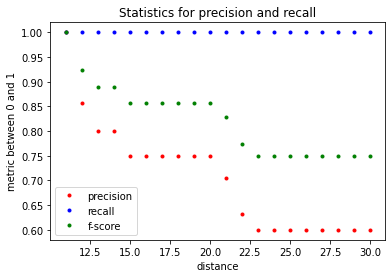

In [20]:
plt.figure()
plt.title("Statistics for precision and recall")
plt.plot(range(30,10,-1),np.array(list(precision_dict.values())),'r.',label="precision")
plt.plot(range(30,10,-1),np.array(list(recall_dict.values())),'b.',label="recall")
plt.plot(range(30,10,-1),np.array(list(fscore_dict.values())),'g.',label="f-score")
plt.legend()
plt.xlabel("distance")
plt.ylabel("metric between 0 and 1")

In [21]:
best_distance_wr1 = max(fscore_dict, key=fscore_dict.get)
print(best_distance_wr1)

11


###Calculating the best distance for all the writers 


In [22]:
precision_list = []
recall_list = []
fscore_list = []

for w in range(1,31):

  distance_for_matching = 30
  precision_list.append([])
  recall_list.append([])
  fscore_list.append({})

  print("==================================================user"+str(w)+"=================================================")
  enr, ver = writer(w)
  enr = normalize_length_generic(enr)
  ver = normalize_length_generic(ver)

  f_enr = []
  f_ver = []

  for i in range(len(enr)):
    f_enr.append(norm_feature_sg(enr[i])) 

  for i in range(len(ver)):
    f_ver.append(norm_feature_sg(ver[i]))

  for d in range(20):
    
    precision, recall, fscore = dtw_each_user(distance_for_matching, f_enr, f_ver, w)

    precision_list[w-1].append(precision)
    recall_list[w-1].append(recall)
    fscore_list[w-1].update({distance_for_matching : fscore})

    distance_for_matching += -1

==================================================user1=================================================
==================================================user2=================================================
==================================================user3=================================================
==================================================user4=================================================
==================================================user5=================================================
==================================================user6=================================================
==================================================user7=================================================
==================================================user8=================================================
==================================================user9=================================================
==================================================user1

In [23]:
all_min_best_distances = []
all_max_best_distances = []
values = []
for w in range(0,30):
  values = []
  for key, value in fscore_list[w].items():  #accessing values
    values.append(value)
  max_value = max(values)
  first = -1
  last = -1
  for i in range(0,20):
    if(values[i]==max_value):
      if(first==-1):
        first = 30-i
        last = 30-i
      else:
        last = 30-i
  all_min_best_distances.append(last)
  all_max_best_distances.append(first)
print(all_min_best_distances)
print(all_max_best_distances)

[11, 15, 14, 12, 11, 11, 13, 13, 12, 12, 16, 11, 13, 13, 15, 11, 11, 18, 11, 14, 11, 11, 11, 11, 12, 14, 12, 14, 11, 14]
[11, 15, 15, 12, 18, 30, 19, 13, 17, 21, 16, 15, 13, 30, 15, 30, 11, 18, 18, 14, 15, 11, 11, 13, 16, 15, 12, 14, 11, 17]


/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warnin

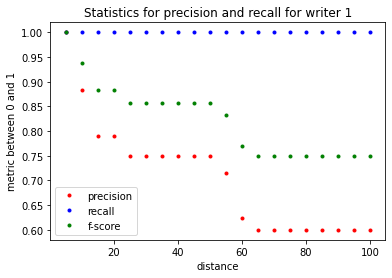

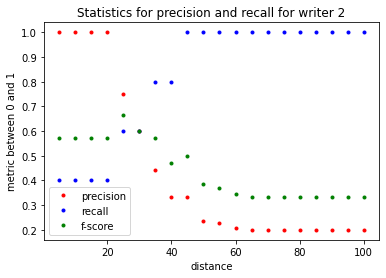

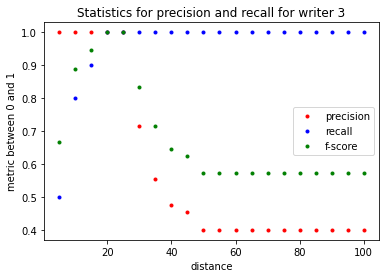

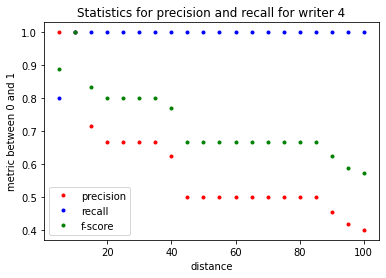

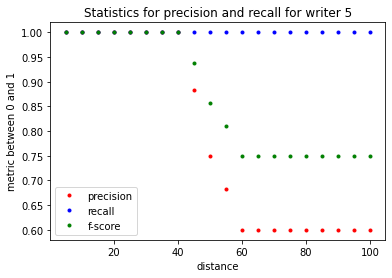

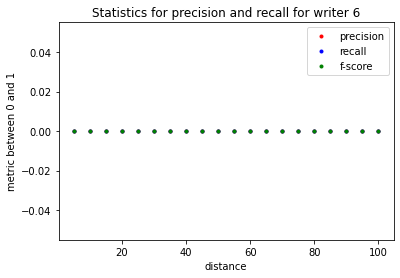

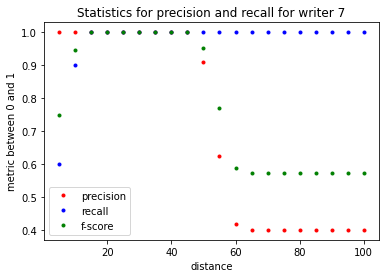

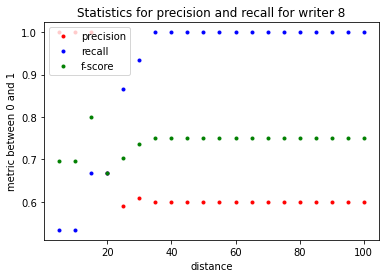

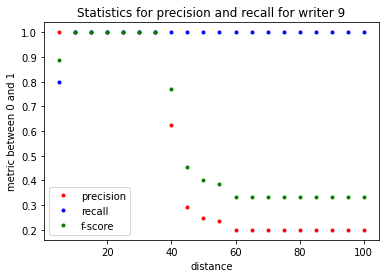

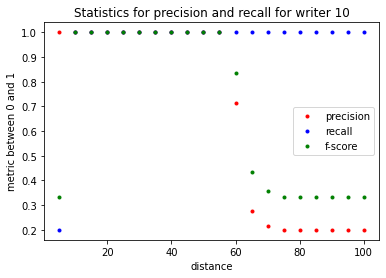

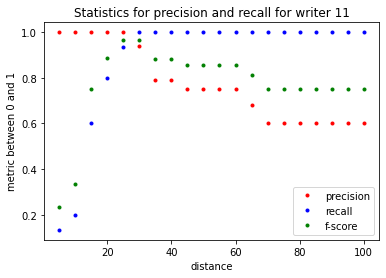

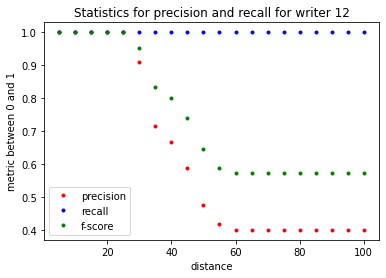

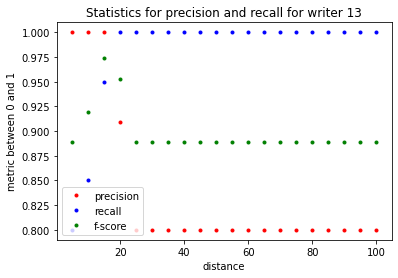

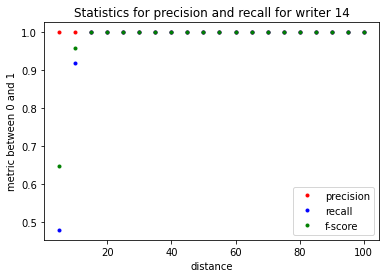

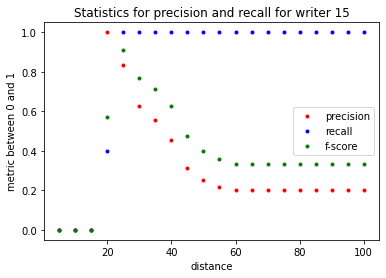

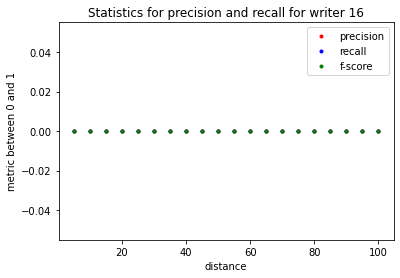

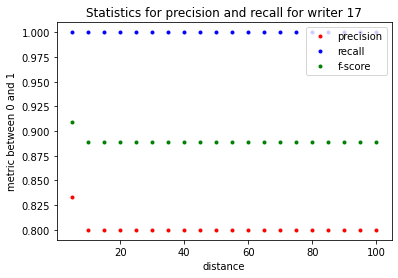

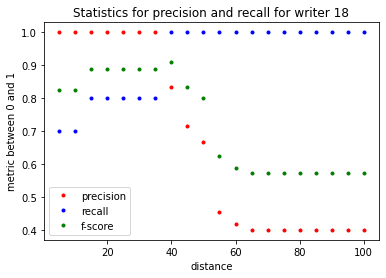

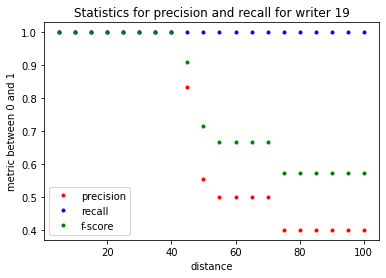

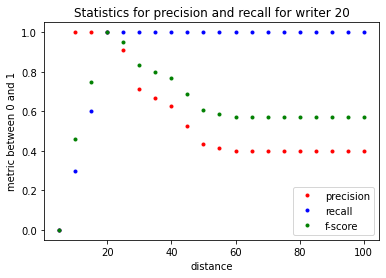

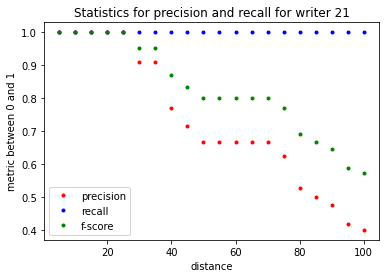

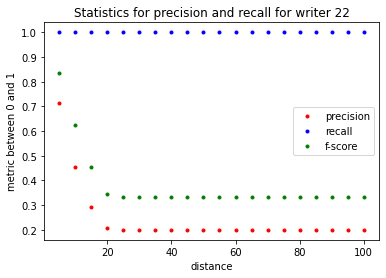

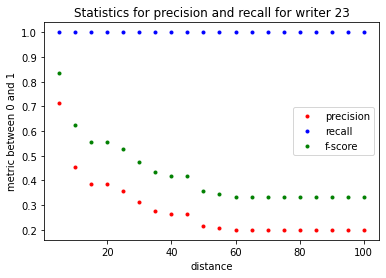

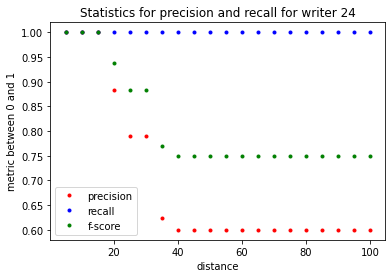

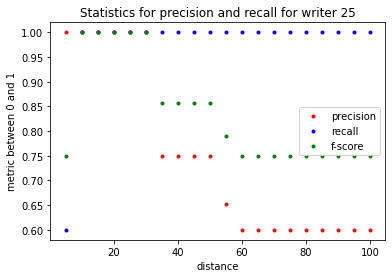

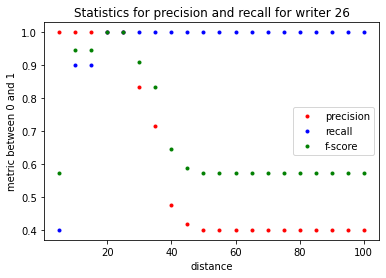

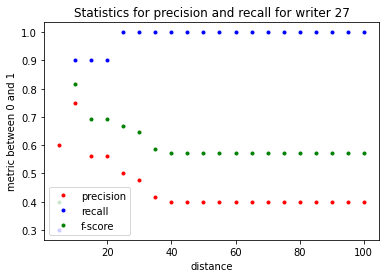

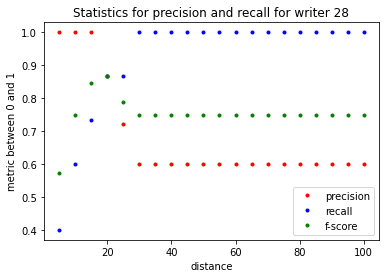

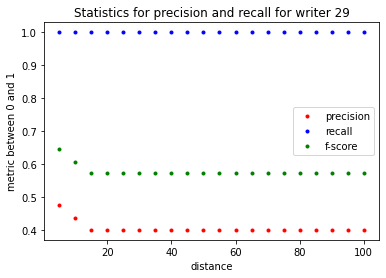

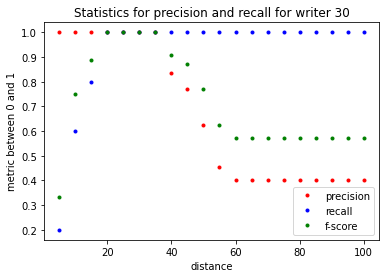

In [24]:
for w in range(1,31):
  plt.figure()
  plt.title("Statistics for precision and recall for writer " + str(w))
  plt.plot(range(100,0,-5),precision_list[w-1],'r.',label="precision")
  plt.plot(range(100,0,-5),recall_list[w-1],'b.',label="recall")
  plt.plot(range(100,0,-5),np.array(list(fscore_list[w-1].values())),'g.',label="f-score")
  plt.legend()
  plt.xlabel("distance")
  plt.ylabel("metric between 0 and 1")

# Calculation for the whole dataset with the best distance of writer1.

In [25]:
# calculate avg presicion for all users with best distance matching of writer1
distance_for_matching = best_distance_wr1   
avg_recall, avg_precision, avg_fscore = dtw_user(distance_for_matching)
print(avg_recall,avg_precision,avg_fscore)

0.5948888888888888 0.8112698412698413 0.6412776310779775


# Generalization of the distance. We try to find the unique best distance for all writers.

In [26]:
# Use the best distances of the individual writers to find a general unique value that maximize the f-score.
num_epoch= 60
min_best_dist=min(all_min_best_distances)
max_best_dist=max(all_max_best_distances)
steps = (max_best_dist-min_best_dist)/(num_epoch-1)
all_avg_distance, all_avg_recall, all_avg_precision, all_avg_fscore = epoch_all_user(num_epoch, steps, max_best_dist)
print(all_avg_distance,all_avg_recall,all_avg_precision, all_avg_fscore)

epoch1
epoch2
epoch3
epoch4
epoch5
epoch6
epoch7
epoch8
epoch9
epoch10
epoch11
epoch12
epoch13
epoch14
epoch15
epoch16
epoch17
epoch18
epoch19
epoch20
epoch21
epoch22
epoch23
epoch24
epoch25
epoch26
epoch27
epoch28
epoch29
epoch30
epoch31
epoch32
epoch33
epoch34
epoch35
epoch36
epoch37
epoch38
epoch39
epoch40
epoch41
epoch42
epoch43
epoch44
epoch45
epoch46
epoch47
epoch48
epoch49
epoch50
epoch51
epoch52
epoch53
epoch54
epoch55
epoch56
epoch57
epoch58
epoch59
epoch60
[30, 29.677966101694917, 29.355932203389834, 29.03389830508475, 28.711864406779668, 28.389830508474585, 28.067796610169502, 27.74576271186442, 27.423728813559336, 27.101694915254253, 26.77966101694917, 26.457627118644087, 26.135593220339004, 25.81355932203392, 25.491525423728838, 25.169491525423755, 24.847457627118672, 24.52542372881359, 24.203389830508506, 23.881355932203423, 23.55932203389834, 23.237288135593257, 22.915254237288174, 22.59322033898309, 22.271186440678008, 21.949152542372925, 21.627118644067842, 21.30508474

Text(0, 0.5, 'metric between 0 and 1')

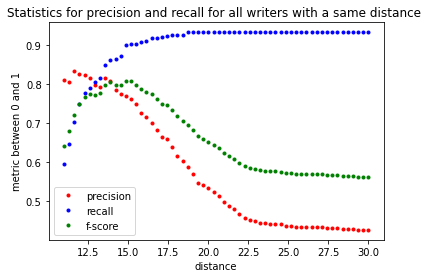

In [27]:
# Graph of the tested general distances
plt.figure()
plt.title("Statistics for precision and recall for all writers with a same distance ")
plt.plot(all_avg_distance,all_avg_precision,'r.',label="precision")
plt.plot(all_avg_distance,all_avg_recall,'b.',label="recall")
plt.plot(all_avg_distance,all_avg_fscore,'g.',label="f-score")
plt.legend()
plt.xlabel("distance")
plt.ylabel("metric between 0 and 1")

In [28]:
best_distance_whole_set = all_avg_distance[(all_avg_fscore.index(max(all_avg_fscore)))]
print(best_distance_whole_set)
distance_for_matching = best_distance_whole_set  
avg_whole_recall, avg_whole_precision, avg_whole_fscore = dtw_user(distance_for_matching)
print("Final results:")
print("Recall with the distance of writer1 : "+str(avg_recall)+", recall with the generalized distance : "+str(avg_whole_recall))
print("Precision with the distance of writer1 : "+str(avg_precision)+", precision with the generalized distance : "+str(avg_whole_precision))
print("F-score with the distance of writer1 : "+str(avg_fscore)+", f-score with the generalized distance : "+str(avg_whole_fscore))

14.864406779661092
Final results:
Recall with the distance of writer1 : 0.5948888888888888, recall with the generalized distance : 0.9
Precision with the distance of writer1 : 0.8112698412698413, precision with the generalized distance : 0.7703774141235441
F-score with the distance of writer1 : 0.6412776310779775, f-score with the generalized distance : 0.8091939828433639
